# 03 Exploratory analysis: listing durations and a sector heatmap

Early exploration, kept for reference. Notebooks 04 to 06 do not depend on it.

In [1]:
from pathlib import Path
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
STOCK_DATA_PATH = Path("../data/processed/panel_sp500_membership")

## How long each stock was in the index

In [3]:
# Create a bar chart showing the length of time each stock has been listed on the S&P 500

bar_chart_data = []
for file in STOCK_DATA_PATH.glob("*.csv"):
    ticker = file.stem.upper()
    df = pd.read_csv(file)
    
    # First and last date the stock appears in the membership panel
    start_date = df['date'].min()
    end_date = df['date'].max()

    bar_chart_data.append((ticker, start_date, end_date))

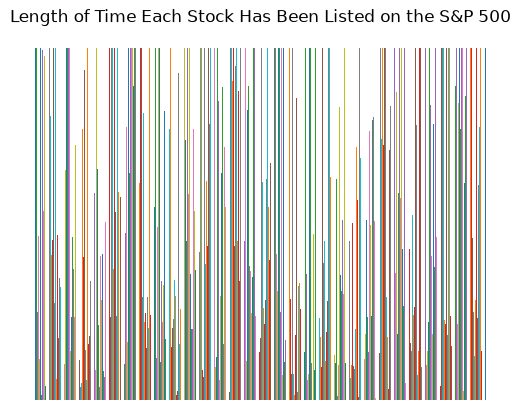

In [4]:
for ticker, start_date, end_date in bar_chart_data:
    plt.bar(ticker, (pd.to_datetime(end_date) - pd.to_datetime(start_date)).days)

plt.axis('off')
plt.title("Length of Time Each Stock Has Been Listed on the S&P 500")
plt.xticks(rotation=90)
plt.savefig("../figures/stock_listing_duration.png", dpi=300)
plt.show()

Membership turns over a lot. Between its first and last day in the index, the median stock spans about 9.5 of the 21 years, and only about a quarter span 19 years or more. That turnover is why the analysis cuts each stock to its membership window and keeps stocks that did not last the whole period.

## Correlation heatmap by sector

A first look at which stocks move together. Stocks are ordered by sector, so a sector whose members move together shows up as a block on the diagonal.

### Correlation matrix 

In [5]:
sector_df = pd.read_csv("../data/raw/ticker_to_sector.csv")

I compute correlations from daily returns. Most prices trend upwards over 20 years, so correlating price levels would make almost every pair look strongly related.

In [6]:
import pandas as pd

# Collect all close-price series
price_series = {}

for file in STOCK_DATA_PATH.glob("*.csv"):
    ticker = file.stem.upper()

    df = pd.read_csv(
        file,
        parse_dates=["date"]
    )

    price_series[ticker] = (
        df.set_index("date")["close"]
    )

# Build DataFrame in one operation
prices = pd.DataFrame(price_series)

# Align dates and remove incomplete stocks
prices = prices.sort_index()
prices = prices.dropna(axis=1)

# Daily returns

# Correlation matrix
returns = prices.pct_change(fill_method=None)

corr_matrix = returns.corr(min_periods=252)

### Aligning the sectors

In [7]:
sector_df = sector_df[
    sector_df["Ticker"].isin(corr_matrix.index)
].copy()

sector_df = sector_df.sort_values(
    ["Sector", "Ticker"]
)

ordered_tickers = sector_df["Ticker"].tolist()

corr_matrix = corr_matrix.loc[
    ordered_tickers,
    ordered_tickers
]


sector_sizes = (
    sector_df.groupby("Sector")
    .size()
)

boundaries = sector_sizes.cumsum()

starts = boundaries - sector_sizes

sector_centers = (
    starts + sector_sizes / 2
)

### Plotting the heatmap

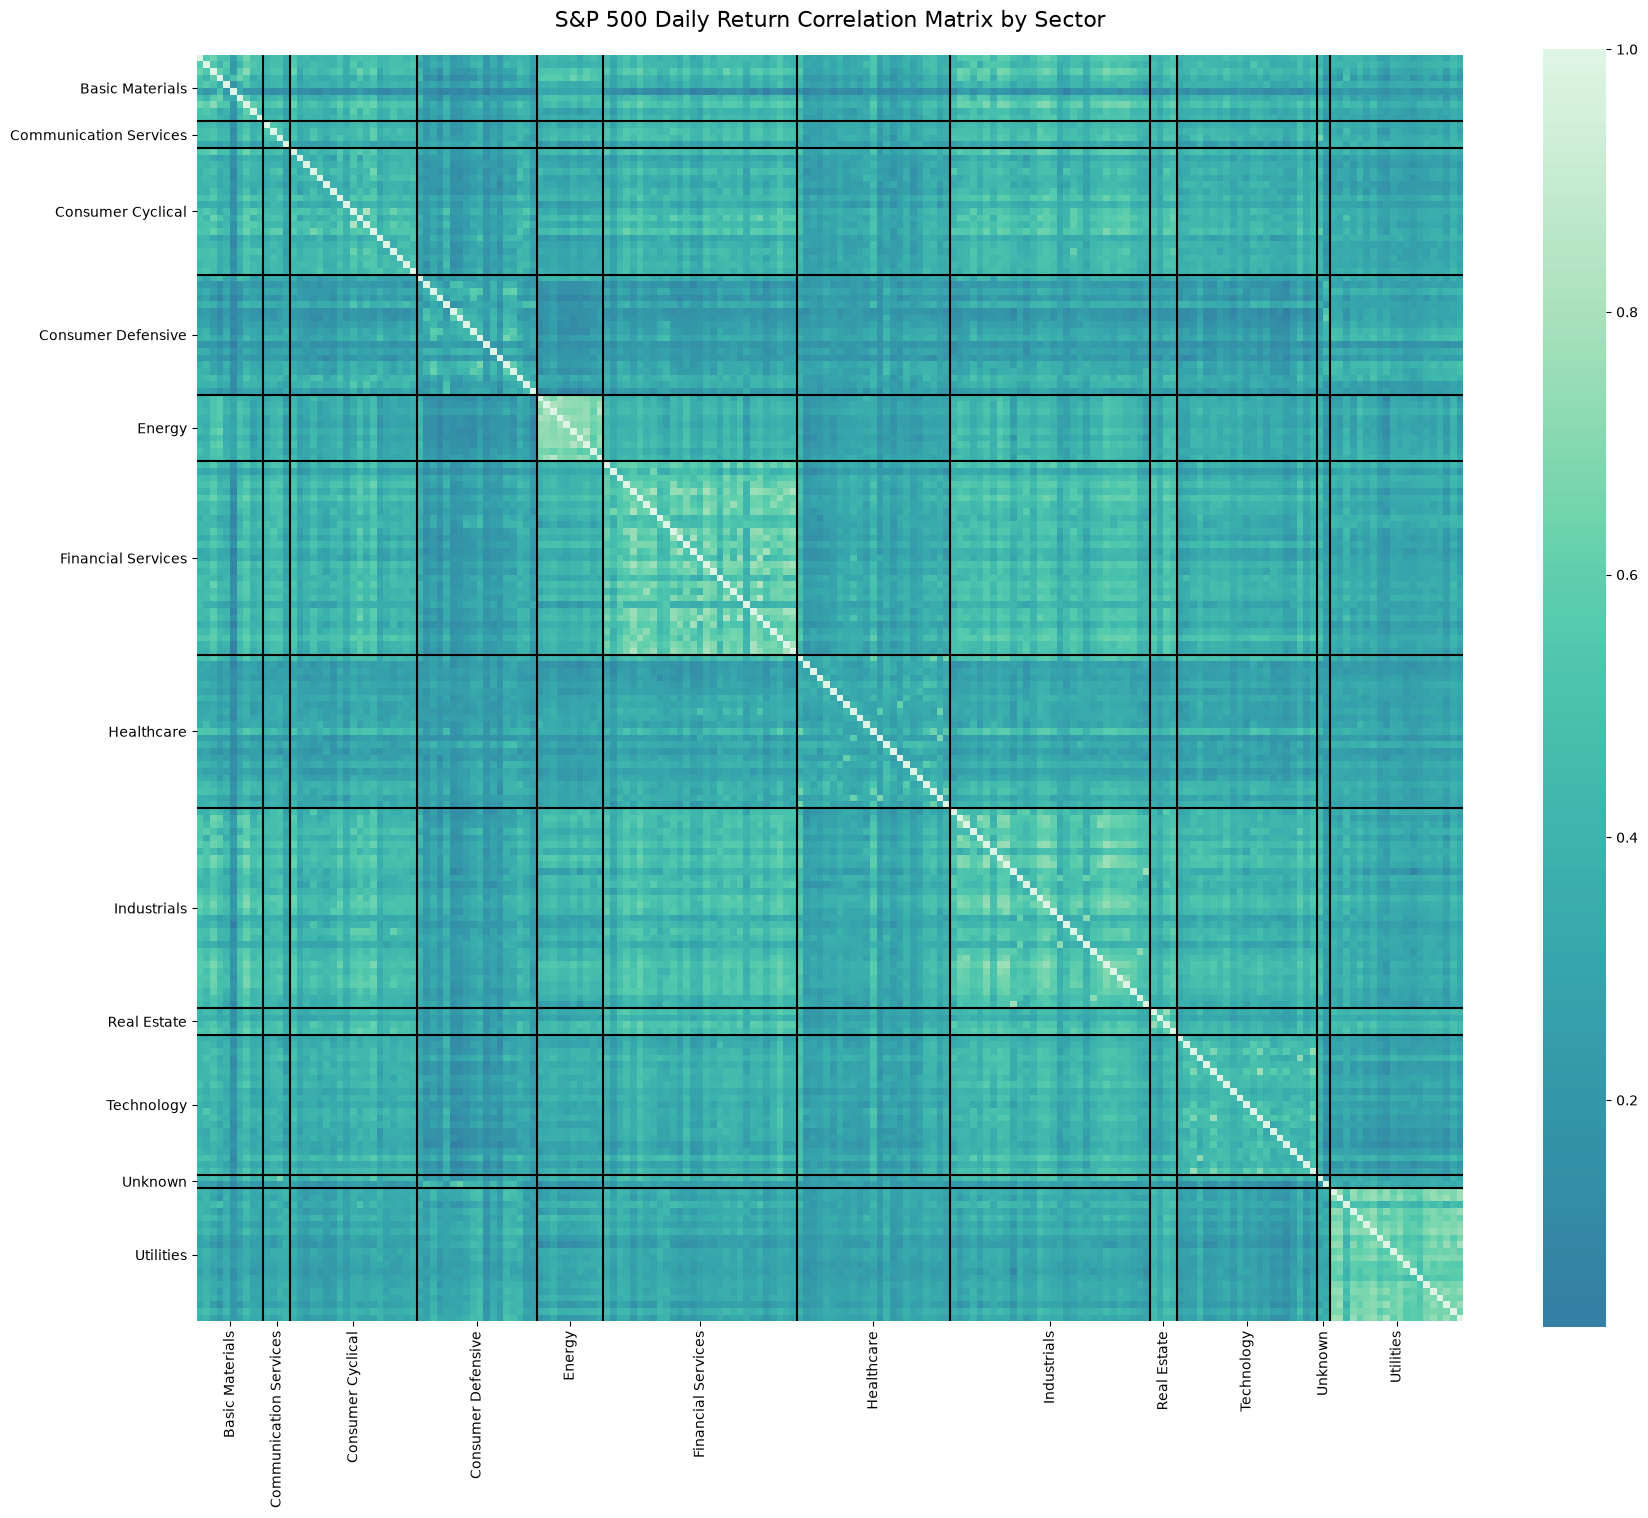

In [8]:
plt.figure(figsize=(18, 15))

ax = sns.heatmap(
    corr_matrix,
    cmap="mako",
    center=0,
    xticklabels=False,
    yticklabels=False,
    square=True
)

# Draw sector separator lines
for boundary in boundaries[:-1]:
    ax.axhline(
        boundary,
        color="black",
        linewidth=1.5
    )

    ax.axvline(
        boundary,
        color="black",
        linewidth=1.5
    )

# Add sector labels
ax.set_yticks(sector_centers)
ax.set_yticklabels(
    sector_sizes.index,
    fontsize=10,
    rotation=0
)

ax.set_xticks(sector_centers)
ax.set_xticklabels(
    sector_sizes.index,
    fontsize=10,
    rotation=90
)

plt.title(
    "S&P 500 Daily Return Correlation Matrix by Sector",
    fontsize=16,
    pad=20
)

plt.tight_layout()
plt.savefig("../figures/correlation_matrix_by_sector.png", dpi=300)
plt.show()
